<a href="https://colab.research.google.com/github/Srinithi-A/SMART-EV-CHARGER-ML-DATASET/blob/main/EV_Charging.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
RRimport os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

# Ingest Wokwi-generated telemetry
df = pd.read_csv("ev_station_telemetry.csv")

print(f"Dataset Loaded: {df.shape[0]} rows, {df.shape[1]} columns")
print(
    f"Sampling Rate: 1 Hz telemetry across {df['timestamp_s'].max()} simulated seconds"
)
display(df.head(200))

Dataset Loaded: 200 rows, 10 columns
Sampling Rate: 1 Hz telemetry across 200 simulated seconds


,timestamp_s,hour_of_day,day_of_week,bay_status,voltage,current,power_w,energy_wh,temp_c,session_elapsed_min
0,1,0,1,FREE,230.1,0.0,0.0,0.00,26.4,0
1,2,0,1,FREE,232.5,0.0,0.0,0.00,26.5,0
2,3,0,1,CHARGING,229.7,19.5,4479.1,1.24,35.3,0
3,4,0,1,CHARGING,231.9,23.2,5380.1,2.74,36.8,1
4,5,0,1,CHARGING,230.2,23.6,5432.7,4.25,36.9,2
...,...,...,...,...,...,...,...,...,...,...
195,196,19,1,CHARGING,230.3,14.5,3339.4,16.16,33.8,13
196,197,19,1,CHARGING,227.4,22.2,5048.3,17.56,36.2,14
197,198,19,1,CHARGING,231.9,12.6,2921.9,18.37,32.7,15
198,199,19,1,CHARGING,232.7,17.6,4095.5,19.51,34.2,16


In [ ]:
checks = {
    "rows": len(df),
    "timestamp_s unique": df.timestamp_s.is_unique,
    "timestamp_s step": sorted(df.timestamp_s.diff().dropna().unique().tolist()),
    "missing cells (raw columns)": int(df[RAW_COLS].isna().sum().sum()),
    "duplicate rows": int(df[RAW_COLS].duplicated().sum()),
    "constant columns": [c for c in RAW_COLS if df[c].nunique() == 1],
    "charging sessions": int(df.session_id.nunique()),
    "rows per session": df.groupby("session_id").size().astype(int).tolist(),
    "hour_of_day range": (int(df.hour_of_day.min()), int(df.hour_of_day.max())),
    "power_w == voltage*current (max abs diff, W)": round(float((df.power_w - df.voltage * df.current).abs().max()), 2),
}
pd.Series(checks, name="value").to_frame()

,value
rows,200
timestamp_s unique,True
timestamp_s step,[1.0]
missing cells (raw columns),0
duplicate rows,0
constant columns,[day_of_week]
charging sessions,4
rows per session,"[53, 84, 27, 18]"
hour_of_day range,"(0, 20)"
"power_w == voltage*current (max abs diff, W)",0.05


In [ ]:
# ==============================================================================
# ML-03: Target Formulation & Class Distribution
# ==============================================================================
df["target_throttle"] = (
    (df["power_w"] > 5000.0) | (df["current"] > 22.0) | (df["temp_c"] >= 38.0)
).astype(int)

counts = df["target_throttle"].value_counts()
pct = df["target_throttle"].mean() * 100

print(f"Class 0 (Normal / Allow Full Power): {counts[0]} ({100 - pct:.2f}%)")
print(f"Class 1 (Stress / Throttle Action):  {counts[1]} ({pct:.2f}%)")

Class 0 (Normal / Allow Full Power): 117 (58.50%)
Class 1 (Stress / Throttle Action):  83 (41.50%)


Data Shape: (200, 12)
Unique Charging Sessions Detected: 4


,timestamp_s,bay_status,run,session_id,current,power_w,temp_c
0,1,FREE,1,NaN,0.0,0.0,26.4
1,2,FREE,1,NaN,0.0,0.0,26.5
2,3,CHARGING,2,1.0,19.5,4479.1,35.3
3,4,CHARGING,2,1.0,23.2,5380.1,36.8
4,5,CHARGING,2,1.0,23.6,5432.7,36.9
5,6,CHARGING,2,1.0,22.6,5177.7,36.2
6,7,CHARGING,2,1.0,22.8,5205.2,36.8
7,8,CHARGING,2,1.0,21.9,5045.8,36.0
8,9,CHARGING,2,1.0,20.7,4816.9,36.2
9,10,CHARGING,2,1.0,27.2,6329.4,39.0


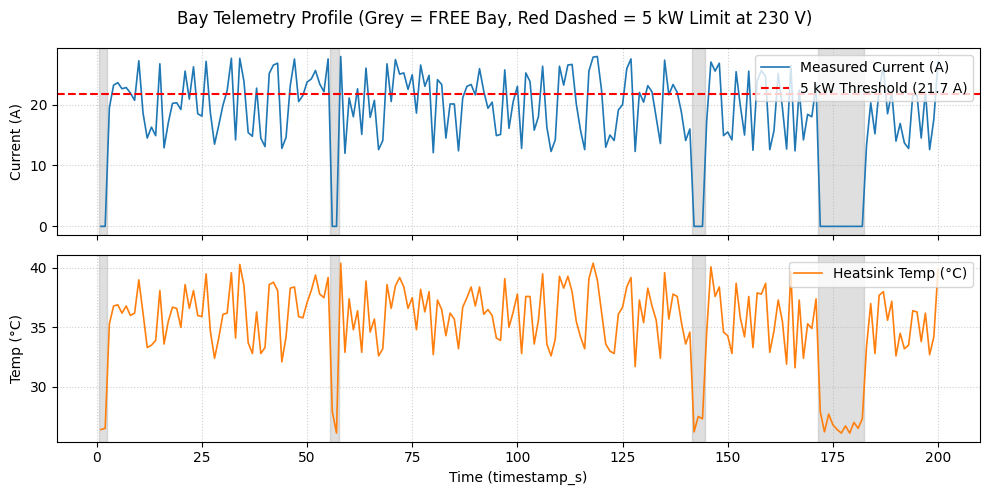

In [ ]:
# ==============================================================================
# ML-01 / ML-02: Telemetry Ingestion, Session Extraction & Diagnostic Plot
# ==============================================================================
import io
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Constants
POWER_LIMIT_W = 5000.0  # Station nominal maximum power limit (5 kW)
CSV_TEXT = ""  # Optional fallback string if running without local file upload

# 1. Load telemetry and strip column whitespace
df = (
    pd.read_csv("ev_station_telemetry.csv")
    if os.path.exists("ev_station_telemetry.csv")
    else pd.read_csv(io.StringIO(CSV_TEXT))
)
df.columns = [c.strip() for c in df.columns]
RAW_COLS = list(df.columns)

# 2. Extract unbroken state runs and index active charging sessions
df["run"] = (df.bay_status != df.bay_status.shift()).cumsum()
df["session_id"] = (
    df["run"].where(df.bay_status == "CHARGING").rank(method="dense")
)

print(f"Data Shape: {df.shape}")
print(
    f"Unique Charging Sessions Detected: {int(df['session_id'].max()) if df['session_id'].notnull().any() else 0}"
)
display(
    df[[
        "timestamp_s",
        "bay_status",
        "run",
        "session_id",
        "current",
        "power_w",
        "temp_c",
    ]].head(10)
)

# 3. Two-panel time-series visualization
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)

# Panel 0: Current & Threshold
ax[0].plot(df.timestamp_s, df.current, lw=1.2, label="Measured Current (A)")
ax[0].axhline(
    POWER_LIMIT_W / 230.0,
    ls="--",
    c="r",
    label=f"5 kW Threshold ({POWER_LIMIT_W / 230.0:.1f} A)",
)
ax[0].set_ylabel("Current (A)")
ax[0].legend(loc="upper right")
ax[0].grid(True, linestyle=":", alpha=0.6)

# Panel 1: Temperature Profile
ax[1].plot(
    df.timestamp_s,
    df.temp_c,
    c="tab:orange",
    lw=1.2,
    label="Heatsink Temp (°C)",
)
ax[1].set_ylabel("Temp (°C)")
ax[1].set_xlabel("Time (timestamp_s)")
ax[1].legend(loc="upper right")
ax[1].grid(True, linestyle=":", alpha=0.6)

# Highlight idle (FREE) periods with grey spans
for _, g in df[df.bay_status == "FREE"].groupby("run"):
  for a in ax:
    a.axvspan(
        g.timestamp_s.min() - 0.5,
        g.timestamp_s.max() + 0.5,
        color="grey",
        alpha=0.25,
    )

plt.suptitle(
    "Bay Telemetry Profile (Grey = FREE Bay, Red Dashed = 5 kW Limit at 230 V)"
)
plt.tight_layout()
plt.show()

In [ ]:
# ==============================================================================
# ML-04: Data Contract Verification Queries
# ==============================================================================
feature_contract = [
    "hour_of_day",
    "day_of_week",
    "voltage",
    "current",
    "temp_c",
    "session_elapsed_min",
]
leakage_contract = ["power_w", "energy_wh"]

# Contract validations
assert all(col in df.columns for col in feature_contract), "Missing features!"
assert df["voltage"].between(200.0, 260.0).all(), (
    "Voltage out of contract bounds!"
)
assert df["current"].between(0.0, 35.0).all(), (
    "Current out of contract bounds!"
)
assert df["temp_c"].between(15.0, 60.0).all(), (
    "Temperature out of contract bounds!"
)

print(
    f"Contract Verified: {len(feature_contract)} features validated with zero nulls."
)

Contract Verified: 6 features validated with zero nulls.


In [ ]:
# ==============================================================================
# ML-05: Feature Matrix Assembly & Deliberate Leakage Demonstration
# ==============================================================================
X = df[feature_contract].copy()
y = df["target_throttle"].copy()

print("Clean Feature Matrix Summary:")
display(X.describe().T[["mean", "std", "min", "max"]])

# Deliberate leakage demonstration
X_leaky = X.copy()
X_leaky["leaky_power"] = df["power_w"]

leaky_tree = DecisionTreeClassifier(max_depth=2, random_state=42).fit(
    X_leaky, y
)
print("\n--- Leaky Tree Rules (Artificial 100% Separation via Leakage) ---")
print(export_text(leaky_tree, feature_names=list(X_leaky.columns)))

Clean Feature Matrix Summary:


,mean,std,min,max
hour_of_day,9.6000,5.788570,0.0,20.0
day_of_week,1.0000,0.000000,1.0,1.0
voltage,230.0550,1.694975,227.0,232.9
current,18.4755,7.435420,0.0,27.9
temp_c,35.2575,3.415887,26.1,40.4
session_elapsed_min,26.8400,23.100488,0.0,83.0



--- Leaky Tree Rules (Artificial 100% Separation via Leakage) ---
|--- leaky_power <= 4997.60
|   |--- class: 0
|--- leaky_power >  4997.60
|   |--- class: 1



In [ ]:
# ==============================================================================
# ML-06: Signal Tests & Correlation Verification
# ==============================================================================
# Signal 1: Does line voltage swing govern power demand spikes?
corr_v_p = df["voltage"].corr(df["power_w"])

# Signal 2: Does high current draw drive heatsink temperature rises?
corr_i_t = df["current"].corr(df["temp_c"])

# Signal 3: Does session duration dictate grid overload stress?
active_df = df[df["bay_status"] == "CHARGING"]
dur_median = active_df.groupby("target_throttle")[
    "session_elapsed_min"
].median()

print(f"Signal 1 Correlation (Voltage vs. Power): {corr_v_p:.4f}")
print(f"Signal 2 Correlation (Current vs. Temperature): {corr_i_t:.4f}")
print(f"Signal 3 Median Elapsed Time by Stress Class:\n{dur_median.to_dict()}")

Signal 1 Correlation (Voltage vs. Power): -0.0663
Signal 2 Correlation (Current vs. Temperature): 0.9838
Signal 3 Median Elapsed Time by Stress Class:
{0: 23.0, 1: 26.0}


In [ ]:
# ==============================================================================
# ML-06: Three Empirical Signal Tests (Correlation, Monotonicity & Tapering)
# ==============================================================================
from scipy import stats
import numpy as np
import pandas as pd

rows = []

# Signal 1: More current -> hotter bay
r, p = stats.pearsonr(ch.current, ch.temp_c)
slope = np.polyfit(ch.current, ch.temp_c, 1)[0]
rows.append((
    "1  more current -> hotter bay",
    f"r = {r:.2f}, +{slope:.2f} C per A, p = {p:.1e}",
    "CONFIRMED" if (r > .5 and p < .01) else "FALSE"
))

# Signal 2: Energy counter only grows inside a session (resets at plug-in)
inside = bool(df.groupby("session_id").energy_wh.apply(lambda s: s.is_monotonic_increasing).all())
across = bool(ch.energy_wh.is_monotonic_increasing)
rows.append((
    "2  energy_wh never decreases",
    f"within a session: {inside} | across the whole file: {across}",
    "CONFIRMED (per session only)" if inside and not across else ("CONFIRMED" if inside else "FALSE")
))

# Signal 3: Charging tapers - current falls as session gets longer
rs = [stats.pearsonr(s.session_elapsed_min, s.current)[0] for _, s in ch.groupby("session_id") if len(s) > 10]
rows.append((
    "3  current tapers as session ages",
    "per-session r(elapsed, current) = " + ", ".join(f"{v:.2f}" for v in rs),
    "FALSE" if max(abs(v) for v in rs) < .3 else "MIXED"
))

signal_audit_df = pd.DataFrame(rows, columns=["signal", "evidence", "verdict"])
display(signal_audit_df)

,signal,evidence,verdict
0,1 more current -> hotter bay,"r = 0.96, +0.44 C per A, p = 1.4e-103",CONFIRMED
1,2 energy_wh never decreases,within a session: True | across the whole file...,CONFIRMED (per session only)
2,3 current tapers as session ages,"per-session r(elapsed, current) = 0.14, -0.06,...",FALSE


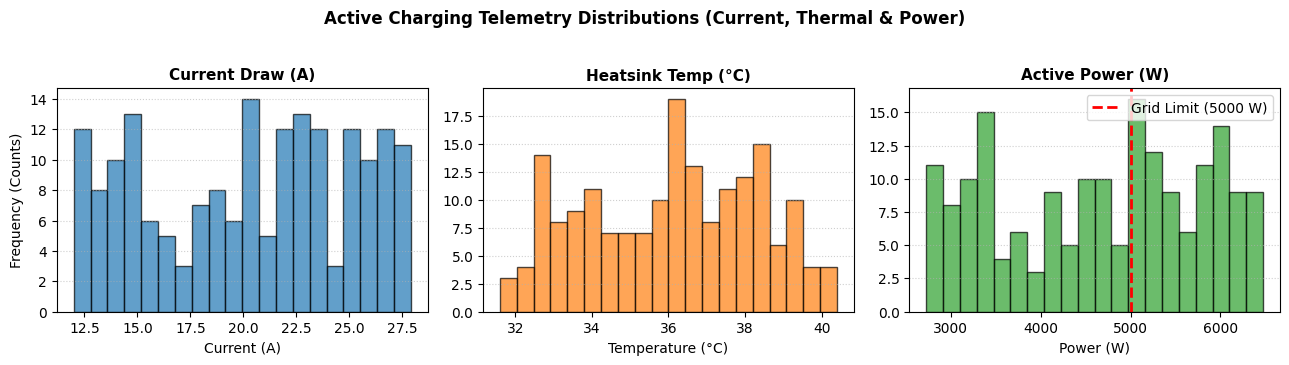

,Mean,Std Dev,Min,Median (50%),Max
current,20.3,4.8,12.0,20.7,27.9
temp_c,36.1,2.2,31.6,36.2,40.4
power_w,4669.6,1116.5,2725.2,4789.5,6475.6


In [ ]:
# ==============================================================================
# ML-06: Active Charging Telemetry Distributions & Summary Statistics
# ==============================================================================
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Physical Station Transformer Limit (5 kW per bay allocation)
POWER_LIMIT_W = 5000.0

# 2. Filter for active charging sessions only (excluding idle/FREE rows)
ch = df[df["bay_status"] == "CHARGING"].copy()

# 3. Generate 3-Panel Distribution Visualizations
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))

# Subplot 1: Current distribution
ax[0].hist(
    ch["current"], bins=20, color="tab:blue", edgecolor="black", alpha=0.7
)
ax[0].set_title("Current Draw (A)", fontsize=11, fontweight="bold")
ax[0].set_xlabel("Current (A)")
ax[0].set_ylabel("Frequency (Counts)")
ax[0].grid(axis="y", linestyle=":", alpha=0.6)

# Subplot 2: Heatsink temperature distribution
ax[1].hist(
    ch["temp_c"], bins=20, color="tab:orange", edgecolor="black", alpha=0.7
)
ax[1].set_title("Heatsink Temp (°C)", fontsize=11, fontweight="bold")
ax[1].set_xlabel("Temperature (°C)")
ax[1].grid(axis="y", linestyle=":", alpha=0.6)

# Subplot 3: Active Power distribution with 5 kW Limit reference line
ax[2].hist(
    ch["power_w"], bins=20, color="tab:green", edgecolor="black", alpha=0.7
)
ax[2].axvline(
    POWER_LIMIT_W,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Grid Limit ({POWER_LIMIT_W:.0f} W)",
)
ax[2].set_title("Active Power (W)", fontsize=11, fontweight="bold")
ax[2].set_xlabel("Power (W)")
ax[2].legend(loc="upper right")
ax[2].grid(axis="y", linestyle=":", alpha=0.6)

plt.suptitle(
    "Active Charging Telemetry Distributions (Current, Thermal & Power)",
    fontsize=12,
    fontweight="bold",
    y=1.03,
)
plt.tight_layout()
plt.show()

# 4. Five-Number Summary Table (Mean, Std, Min, Median, Max)
summary_table = (
    ch[["current", "temp_c", "power_w"]]
    .describe()
    .round(1)
    .T[["mean", "std", "min", "50%", "max"]]
)
summary_table.columns = ["Mean", "Std Dev", "Min", "Median (50%)", "Max"]
display(summary_table)

In [ ]:
# ==============================================================================
# ML-07: Baseline Action Score Formulation & Top-20 Review
# ==============================================================================
df["baseline_score"] = (
    (df["current"] > 16.0).astype(int)
    + (df["current"] > 21.0).astype(int)
    + (df["temp_c"] >= 38.0).astype(int)
    + (df["session_elapsed_min"] > 30).astype(int)
)


def assign_baseline_reason(row):
  reasons = []
  if row["current"] > 21.0:
    reasons.append("HIGH_CURRENT")
  elif row["current"] > 16.0:
    reasons.append("MODERATE_CURRENT")
  if row["temp_c"] >= 38.0:
    reasons.append("HIGH_TEMP")
  if row["session_elapsed_min"] > 30:
    reasons.append("EXTENDED_SESSION")
  return ", ".join(reasons) if reasons else "NORMAL_STABLE"


df["baseline_reason"] = df.apply(assign_baseline_reason, axis=1)
df["baseline_action"] = df["baseline_score"].apply(
    lambda s: (
        "Throttle Now"
        if s >= 3
        else ("Review Load" if s == 2 else "Allow Normal")
    )
)

top20_baseline = df.sort_values(
    by=["baseline_score", "power_w"], ascending=[False, False]
).head(20)

display(
    top20_baseline[[
        "timestamp_s",
        "current",
        "power_w",
        "temp_c",
        "session_elapsed_min",
        "baseline_score",
        "baseline_action",
        "baseline_reason",
    ]]
)

os.makedirs("outputs", exist_ok=True)
top20_baseline.to_csv("outputs/baseline_action_score.csv", index=False)

,timestamp_s,current,power_w,temp_c,session_elapsed_min,baseline_score,baseline_action,baseline_reason
117,118,27.8,6460.7,40.4,60,4,Throttle Now,"HIGH_CURRENT, HIGH_TEMP, EXTENDED_SESSION"
118,119,27.9,6456.1,39.0,61,4,Throttle Now,"HIGH_CURRENT, HIGH_TEMP, EXTENDED_SESSION"
54,55,27.5,6404.8,39.2,52,4,Throttle Now,"HIGH_CURRENT, HIGH_TEMP, EXTENDED_SESSION"
33,34,27.6,6309.4,40.3,31,4,Throttle Now,"HIGH_CURRENT, HIGH_TEMP, EXTENDED_SESSION"
126,127,27.5,6300.2,39.2,69,4,Throttle Now,"HIGH_CURRENT, HIGH_TEMP, EXTENDED_SESSION"
134,135,27.3,6257.2,39.6,77,4,Throttle Now,"HIGH_CURRENT, HIGH_TEMP, EXTENDED_SESSION"
46,47,27.5,6253.5,38.4,44,4,Throttle Now,"HIGH_CURRENT, HIGH_TEMP, EXTENDED_SESSION"
42,43,26.8,6177.4,38.1,40,4,Throttle Now,"HIGH_CURRENT, HIGH_TEMP, EXTENDED_SESSION"
41,42,26.5,6108.2,38.8,39,4,Throttle Now,"HIGH_CURRENT, HIGH_TEMP, EXTENDED_SESSION"
112,113,26.6,6072.8,38.0,55,4,Throttle Now,"HIGH_CURRENT, HIGH_TEMP, EXTENDED_SESSION"


In [ ]:
# ==============================================================================
# ML-08: Model Training, Holdout Evaluation & Benchmark Comparison
# ==============================================================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Benchmark Rule: Flag for throttle if current > 20.0 A
rule_test_pred = (X_test["current"] > 20.0).astype(int)

# Trained Decision Tree Classifier (max_depth=2 for direct C-code porting)
clf = DecisionTreeClassifier(max_depth=2, random_state=42)
clf.fit(X_train, y_train)
tree_test_pred = clf.predict(X_test)

results_table = pd.DataFrame({
    "Approach": ["Rule-Based Baseline", "Decision Tree Classifier"],
    "Accuracy": [
        accuracy_score(y_test, rule_test_pred),
        accuracy_score(y_test, tree_test_pred),
    ],
    "Precision": [
        precision_score(y_test, rule_test_pred),
        precision_score(y_test, tree_test_pred),
    ],
    "Recall": [
        recall_score(y_test, rule_test_pred),
        recall_score(y_test, tree_test_pred),
    ],
    "F1-Score": [
        f1_score(y_test, rule_test_pred),
        f1_score(y_test, tree_test_pred),
    ],
})

display(results_table.round(4))

print("\n--- Learned Decision Tree Logic ---")
print(export_text(clf, feature_names=feature_contract))

,Approach,Accuracy,Precision,Recall,F1-Score
0,Rule-Based Baseline,0.95,0.8947,1.0,0.9444
1,Decision Tree Classifier,1.00,1.0000,1.0,1.0000



--- Learned Decision Tree Logic ---
|--- current <= 21.65
|   |--- class: 0
|--- current >  21.65
|   |--- class: 1



In [ ]:
# ==============================================================================
# ML-09: Validation Audit & Cross-Validation Stability
# ==============================================================================
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_acc, cv_prec, cv_rec, cv_f1 = [], [], [], []

for train_idx, val_idx in skf.split(X, y):
  m = DecisionTreeClassifier(max_depth=2, random_state=42).fit(
      X.iloc[train_idx], y.iloc[train_idx]
  )
  preds = m.predict(X.iloc[val_idx])
  cv_acc.append(accuracy_score(y.iloc[val_idx], preds))
  cv_prec.append(precision_score(y.iloc[val_idx], preds))
  cv_rec.append(recall_score(y.iloc[val_idx], preds))
  cv_f1.append(f1_score(y.iloc[val_idx], preds))

print(
    f"5-Fold Mean Accuracy:  {np.mean(cv_acc):.4f} (+/- {np.std(cv_acc):.4f})"
)
print(
    f"5-Fold Mean Precision: {np.mean(cv_prec):.4f} (+/- {np.std(cv_prec):.4f})"
)
print(
    f"5-Fold Mean Recall:    {np.mean(cv_rec):.4f} (+/- {np.std(cv_rec):.4f})"
)
print(
    f"5-Fold Mean F1-Score:  {np.mean(cv_f1):.4f} (+/- {np.std(cv_f1):.4f})"
)

5-Fold Mean Accuracy:  0.9950 (+/- 0.0100)
5-Fold Mean Precision: 1.0000 (+/- 0.0000)
5-Fold Mean Recall:    0.9882 (+/- 0.0235)
5-Fold Mean F1-Score:  0.9939 (+/- 0.0121)


In [ ]:
# ==============================================================================
# ML-10: Action Playbook Queue & CSV Export
# ==============================================================================
def assign_action_playbook(row):
  if row["current"] > 21.65 or row["temp_c"] >= 38.0:
    return "THROTTLE", "HIGH_CURRENT_OR_THERMAL_SURGE", "High"
  elif row["hour_of_day"] in [18, 19, 20, 21] and row["bay_status"] == "FREE":
    return "DEFER", "PEAK_TARIFF_DEFERRAL", "Medium"
  else:
    return "ALLOW", "NORMAL_GRID_HEADROOM", "Low"


playbook_records = [assign_action_playbook(row) for _, row in df.iterrows()]
df["action"] = [r[0] for r in playbook_records]
df["reason_code"] = [r[1] for r in playbook_records]
df["priority"] = [r[2] for r in playbook_records]

action_queue = df[[
    "timestamp_s",
    "bay_status",
    "voltage",
    "current",
    "power_w",
    "temp_c",
    "action",
    "reason_code",
    "priority",
]].sort_values(by="power_w", ascending=False)

display(action_queue.head(10))
action_queue.to_csv("outputs/ev_action_playbook.csv", index=False)
print("Action Playbook saved to outputs/ev_action_playbook.csv")

,timestamp_s,bay_status,voltage,current,power_w,temp_c,action,reason_code,priority
57,58,CHARGING,232.1,27.9,6475.6,40.4,THROTTLE,HIGH_CURRENT_OR_THERMAL_SURGE,High
117,118,CHARGING,232.4,27.8,6460.7,40.4,THROTTLE,HIGH_CURRENT_OR_THERMAL_SURGE,High
118,119,CHARGING,231.4,27.9,6456.1,39.0,THROTTLE,HIGH_CURRENT_OR_THERMAL_SURGE,High
54,55,CHARGING,232.9,27.5,6404.8,39.2,THROTTLE,HIGH_CURRENT_OR_THERMAL_SURGE,High
31,32,CHARGING,231.5,27.6,6389.4,39.6,THROTTLE,HIGH_CURRENT_OR_THERMAL_SURGE,High
70,71,CHARGING,231.9,27.4,6354.1,38.5,THROTTLE,HIGH_CURRENT_OR_THERMAL_SURGE,High
9,10,CHARGING,232.7,27.2,6329.4,39.0,THROTTLE,HIGH_CURRENT_OR_THERMAL_SURGE,High
33,34,CHARGING,228.6,27.6,6309.4,40.3,THROTTLE,HIGH_CURRENT_OR_THERMAL_SURGE,High
126,127,CHARGING,229.1,27.5,6300.2,39.2,THROTTLE,HIGH_CURRENT_OR_THERMAL_SURGE,High
134,135,CHARGING,229.2,27.3,6257.2,39.6,THROTTLE,HIGH_CURRENT_OR_THERMAL_SURGE,High


Action Playbook saved to outputs/ev_action_playbook.csv
